# v7 — Augmentasi sinus takikardia sintetis

**Masalah (v3.2).** Semua model menebak ritme teratur ≥ ±115 bpm sebagai AFIB/AFL. Penyebabnya, AFDB hampir tidak punya
ritme Normal yang cepat: hanya 100 dari 99.000 window Normal di atas 120 bpm, dan semuanya tidak teratur. Bobot kelas dan
bias tidak menolong (v3.2: v3.1 95%, v5b 95% alarm palsu pada Normal ≥120 bpm). SMOTE tidak punya bahan untuk dicampur.

**Ide.** Buat contoh "Normal cepat" dari urutan detak Normal **asli** milik pasien latih: waktunya dipadatkan (IBI × s,
s < 1) ke detak target, lalu dipotong 10 detik seperti window asli. Pola variabilitas detak tetap asli, hanya lajunya
dinaikkan. Pasien uji tidak pernah dipakai sebagai sumber data latih sintetis. Sinus takikardia itu teratur, jadi window
sintetis harus punya CV IBI ≤ 0,10 dan detak di dalam rentang target. Segmen berdenyut ektopik dibuang, karena "cepat dan
tidak teratur" adalah ciri AFIB.

| Varian | Data latih | Hipotesis (ditetapkan sebelum melihat hasil) |
|---|---|---|
| **7a. sintetis 100–130 bpm** (utama) | + 6.000 window sintetis per fold | Ambang Normal naik dari 115 ke ≥ 125 bpm, Macro-F1 **tidak lebih buruk** dari v3.1. AFL di AFDB jarang di 100–130 bpm (130 dari 1.152 window), jadi harganya kecil |
| **7b. sintetis 100–160 bpm** (eksploratif) | + 6.000 window sintetis per fold | Ambang naik lebih jauh, tetapi recall AFL turun: AFL 2:1 di AFDB berada di 130–155 bpm dan sama teraturnya |
| kontrol | tanpa sintetis (= resep v5b), ulangan 0 saja | Uji paritas: OOF harus sama dengan v5b |

**Agar adil.**
- Resep bobot lunak (aturan AGENTS.md); fold, seed latih (`2026 + 100·r + k`), hiperparameter, dan window uji sama dengan referensi.
- Fungsi training diimpor dari `v5_training_afl/latih.py`, tidak disalin.
- Referensi = **v3.1**. Ablasi = **v5b** (resep sama tanpa sintetis).
- Protokol v3 + uji stres takikardia v3.2 (wajib, butir 9) + sensitivitas tanpa 04936.

**Kriteria kandidat produksi (ditetapkan sebelum melihat hasil).** Varian layak dikemas (v7.1, dengan persetujuan) bila:
(1) Macro-F1 vs v3.1 tidak lebih buruk (P > 0,05), (2) ambang Normal di uji stres ≥ 125 bpm pada keempat jenis variasi,
(3) recall AFL per pasien tidak runtuh. Trade-off AFL tetap dilaporkan apa adanya.

Biaya: 11 job × 5 fold training (±70 menit GPU, bisa dilanjutkan). Tidak menyentuh paket produksi. Logika ada di `augmentasi.py`.

In [1]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import augmentasi as A
cv, T = A.cv, A.T
pd.set_option("display.width", 230)
pd.set_option("display.max_columns", 30)


def fmt(v, nd=3):
    return f"{v[0]:.{nd}f} [{v[1]:.2f}–{v[2]:.2f}]"


def verdict(p):
    return "lebih baik" if p >= .95 else "lebih buruk" if p <= .05 else "tidak terbedakan"

## 1. Urutan detak dan window sintetis

Window sintetis butuh urutan detak yang bersambung, bukan window yang sudah dipotong. `augmentasi.py` mengekstrak ulang urutan
detak 23 rekaman dengan langkah deteksi yang sama dengan v2. Urutan itu **dibuktikan identik**: window yang dipotong darinya
harus sama bit demi bit dengan `../cache/dataset_v2_detector.npz`.

✓ urutan detak identik dengan dataset v2 (3s): {'rekaman': 23, 'detak': 1131380, 'detak Normal': 617560, 'window': 165978}


,window,detak median,CV median,CV p10–p90,detak / window
kelompok,,,,,
sintetis 130,3000,115.136,0.021,0.009–0.053,15–22
sintetis 160,3000,130.250,0.022,0.010–0.055,16–27
Normal asli,99000,69.992,0.025,0.009–0.208,—
AFL asli,1152,139.168,0.030,0.007–0.189,—


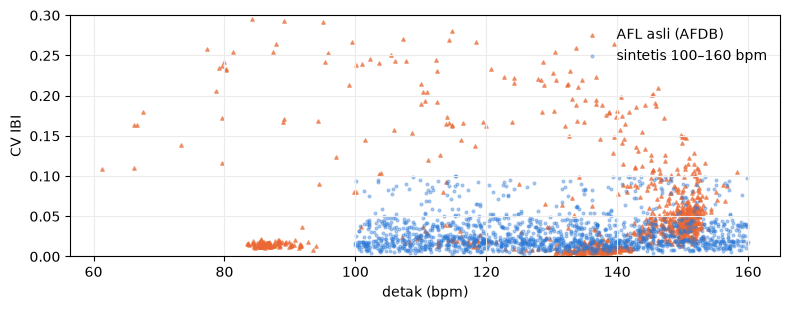

In [2]:
t0 = time.perf_counter()
info = A.build_beats()
print(f"✓ urutan detak identik dengan dataset v2 ({time.perf_counter() - t0:.0f}s):", info)

beats = A.load_beats()
z = np.load(A.DATA_STD)
y, rec = z["y"], z["records"].astype(str)
Mz, Iz = z["M"], z["X"][:, :, 0]
mean_real = (Iz * Mz).sum(1) / Mz.sum(1)
hr_real = 60000 / mean_real
cv_real = np.sqrt((((Iz - mean_real[:, None]) ** 2) * Mz).sum(1) / Mz.sum(1)) / mean_real
rows, examples = [], {}
for v in ("takikardia130", "takikardia160"):
    ibis, hr, src = A.synth_windows(beats, np.unique(rec), 3000, A.VARIANTS[v]["hr"], seed=1)
    cvs = np.array([w.std() / w.mean() for w in ibis]); examples[v] = (hr, cvs)
    rows.append({"kelompok": f"sintetis {v[-3:]}", "window": len(ibis), "detak median": np.median(hr),
                 "CV median": np.median(cvs), "CV p10–p90": f"{np.percentile(cvs, 10):.3f}–{np.percentile(cvs, 90):.3f}",
                 "detak / window": f"{min(map(len, ibis))}–{max(map(len, ibis))}"})
for c, nm in ((0, "Normal asli"), (2, "AFL asli")):
    m = y == c
    rows.append({"kelompok": nm, "window": int(m.sum()), "detak median": np.median(hr_real[m]), "CV median": np.median(cv_real[m]),
                 "CV p10–p90": f"{np.percentile(cv_real[m], 10):.3f}–{np.percentile(cv_real[m], 90):.3f}", "detak / window": "—"})
display(pd.DataFrame(rows).set_index("kelompok").round(3))

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.scatter(hr_real[y == 2], cv_real[y == 2], s=6, color="#eb6834", alpha=.6, label="AFL asli (AFDB)", marker="^")
hr160, cv160 = examples["takikardia160"]
ax.scatter(hr160[:1500], cv160[:1500], s=4, color="#2a78d6", alpha=.35, label="sintetis 100–160 bpm")
ax.set_xlabel("detak (bpm)"); ax.set_ylabel("CV IBI"); ax.set_ylim(0, .3); ax.legend(frameon=False); ax.grid(color="0.92")
plt.tight_layout(); plt.show()

Batas CV 0,10: 22% window Normal asli melebihinya (denyut ektopik), sedangkan 90% window AFIB di atasnya (p10 = 0,13).
Sintetis yang dipadatkan mempertahankan CV sumbernya. Karena itu, di 130–155 bpm ia bertumpuk dengan AFL 2:1 yang teratur.
Ambiguitas ini memang ada di data interval RR, bukan dibuat oleh augmentasi.

## 2. Training (kontrol r0 + 2 varian × 5 ulangan × 5 fold)

OOF varian disimpan ke `../cache/oof_robust/detector_e30_r5_s2026/MicroTransformer_takikardia{130,160}_r*.npz`. Prediksi uji
stres, uji sintetis pasien uji, dan bobot setiap model fold disimpan di `../cache/v7/`. Job yang sudah ada dilewati.

In [3]:
A.run_all_jobs()

0 job tersisa dari 11


## 3. Hasil utama

Semua baris: window uji detektor 50 Hz, rata-rata 5 ulangan, bias cross-fit grid −7…+3, CI 95% bootstrap pasien.

In [4]:
res = A.evaluate()
lab = res["labels"]
order = ["v1", "v31", "bobotlunak", "takikardia130", "takikardia160"]
print("Paritas kontrol (r0) vs v5b:", res["parity"])
display(pd.DataFrame([{"Varian": lab[k], **{m: fmt(res["rows"][k][m]) for m in ("Macro-F1", "AFL F1", "AFL R", "Normal R")},
                       "alarm AFL palsu/jam": fmt(res["episodes"][k]["alarm/jam"]),
                       "deteksi episode AFL": fmt(res["episodes"][k]["deteksi episode"], 2)} for k in order]).set_index("Varian"))
ref_v3 = pd.read_csv(A.OOF_DIR / "ringkasan.csv").set_index("Model").loc["MicroTransformer +bias", "Macro-F1"]
assert ref_v3.startswith(f"{res['rows']['v31']['Macro-F1'][0]:.3f}"), ref_v3
print("✓ Referensi identik dengan v3/v3.1:", ref_v3)

pr = []
for k in ("takikardia130", "takikardia160"):
    for ref, pairs in (("v3.1", res["pairs"][k]), ("v5b", res["pairs_v5"][k])):
        for m in ("Macro-F1", "AFL R", "Normal R"):
            p = pairs[m]
            pr.append({"varian": lab[k], "vs": ref, "metrik": m, "Δ": round(p[0], 3), "CI 95%": f"{p[1]:+.3f} … {p[2]:+.3f}",
                       "P(Δ>0)": round(p[3], 3), "vonis": verdict(p[3])})
display(pd.DataFrame(pr).set_index(["varian", "vs", "metrik"]))

Paritas kontrol (r0) vs v5b: {'selisih prob maks': 0.0, 'prediksi sama': 1.0}


,Macro-F1,AFL F1,AFL R,Normal R,alarm AFL palsu/jam,deteksi episode AFL
Varian,,,,,,
"v1 (sebelum revisi), argmax",0.744 [0.64–0.81],0.399 [0.09–0.59],0.728 [0.37–0.98],0.903 [0.82–0.95],5.101 [2.69–7.89],0.91 [0.73–1.00]
v3.1 referensi,0.832 [0.67–0.92],0.647 [0.17–0.89],0.592 [0.13–0.91],0.924 [0.84–0.97],0.512 [0.10–1.07],0.74 [0.42–0.93]
v5b bobot lunak,0.830 [0.68–0.89],0.637 [0.17–0.80],0.595 [0.16–0.82],0.929 [0.86–0.97],0.542 [0.12–1.10],0.78 [0.52–0.95]
7a: + sintetis 100–130 bpm,0.825 [0.68–0.88],0.618 [0.18–0.76],0.555 [0.14–0.71],0.937 [0.87–0.97],0.577 [0.16–1.17],0.74 [0.42–0.94]
7b: + sintetis 100–160 bpm,0.700 [0.62–0.75],0.275 [0.05–0.39],0.454 [0.21–0.63],0.876 [0.78–0.94],3.931 [2.37–5.47],0.86 [0.75–0.96]


✓ Referensi identik dengan v3/v3.1: 0.832 [0.67–0.92]


Δ           CI 95%  P(Δ>0)             vonis
varian                     vs   metrik                                                    
7a: + sintetis 100–130 bpm v3.1 Macro-F1 -0.006  -0.051 … +0.026   0.412  tidak terbedakan
                                AFL R    -0.036  -0.223 … +0.049   0.366  tidak terbedakan
                                Normal R  0.013  +0.003 … +0.031   1.000        lebih baik
                           v5b  Macro-F1 -0.005  -0.025 … +0.025   0.334  tidak terbedakan
                                AFL R    -0.039  -0.117 … -0.003   0.011       lebih buruk
                                Normal R  0.008  +0.002 … +0.019   1.000        lebih baik
7b: + sintetis 100–160 bpm v3.1 Macro-F1 -0.131  -0.231 … -0.044   0.000       lebih buruk
                                AFL R    -0.138  -0.361 … +0.116   0.098  tidak terbedakan
                                Normal R -0.048  -0.074 … -0.028   0.000       lebih buruk
                           v5b  Macro-F1 -0.130  -0.204 … -0.049   0.000       lebih buruk
                                AFL R    -0.140  -0.255 … +0.088   0.098  tidak terbedakan
                                Normal R -0.053  -0.082 … -0.031   0.000       lebih buruk

## 4. Uji stres takikardia (protokol butir 9)

Ritme teratur sintetis v3.2 (60–170 bpm × 4 jenis variasi, 50 window per titik). Setiap model fold memakai bias cross-fit
fold-nya; proporsi dirata-rata atas semua model fold (varian: 25 model, kontrol: 5). `v31_paket` = paket produksi (v3.2).

,tanpa variasi,seragam ±10 ms,Gauss sd 10 ms,Gauss sd 20 ms
ambang (bpm) < 50% Normal,,,,
v31_paket,115,115,115,115
kontrol,120,120,120,115
takikardia130,135,135,135,135
takikardia160,85,85,85,85


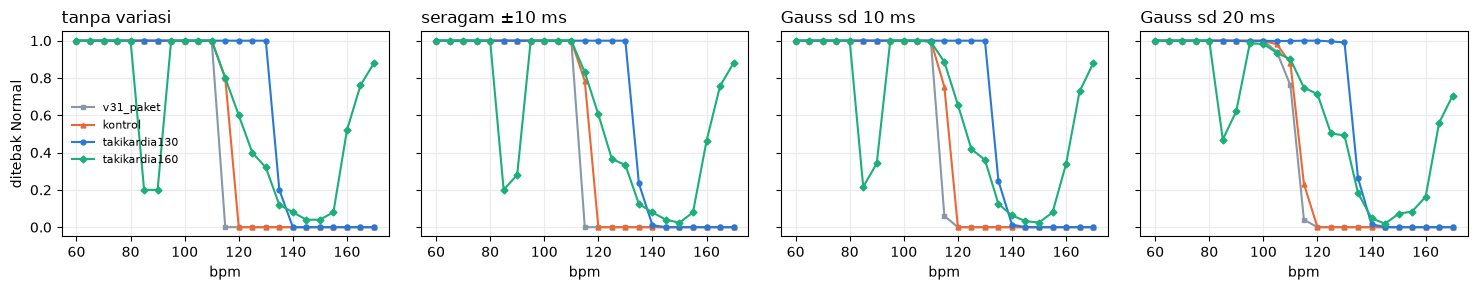

In [5]:
keys = ["v31_paket", "kontrol", "takikardia130", "takikardia160"]
display(pd.DataFrame({k: res["threshold"][k] for k in keys}).T.rename_axis("ambang (bpm) < 50% Normal"))
fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
style = {"v31_paket": ("#8A97A6", "s"), "kontrol": ("#eb6834", "^"), "takikardia130": ("#2a78d6", "o"), "takikardia160": ("#1baf7a", "D")}
for ax, j in zip(axes, res["jitters"]):
    for k in keys:
        ax.plot(res["bpms"], [t[0] for t in res["stress"][k][j]], marker=style[k][1], color=style[k][0], ms=3.5, label=k)
    ax.set_title(j, loc="left"); ax.set_xlabel("bpm"); ax.grid(color="0.92")
axes[0].set_ylabel("ditebak Normal"); axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 5. Sinus takikardia sintetis dari pasien uji

Urutan detak Normal pasien **uji** fold itu, dipadatkan ke 100–160 bpm (1.000 window per fold, window sama untuk semua
varian). Lebih dekat ke variabilitas detak asli daripada uji stres. Angka = proporsi ditebak Normal.

In [6]:
display(pd.DataFrame({k: [res["heldout"][k][b][0] for b in res["ho_bins"]] for k in keys},
                     index=[f"{b} bpm" for b in res["ho_bins"]]).map(lambda v: f"{v:.0%}"))

,v31_paket,kontrol,takikardia130,takikardia160
100–110 bpm,95%,96%,98%,93%
110–120 bpm,30%,49%,98%,78%
120–130 bpm,0%,1%,98%,50%
130–140 bpm,0%,0%,28%,15%
140–150 bpm,0%,0%,0%,4%
150–160 bpm,0%,0%,0%,28%


## 6. Window asli per pita detak dan per pasien AFL

In [7]:
by = res["by_hr"]
sel = [k for k in by if k.startswith("Normal") or k.startswith("AFL")]
display(pd.DataFrame([{"kelas | pita": k, "window": by[k]["n"],
                       **{lab[m]: f"{by[k][m][0]:.0%} / {by[k][m][1]:.0%} / {by[k][m][2]:.0%}"
                          for m in ("v31", "bobotlunak", "takikardia130", "takikardia160")}} for k in sel]).set_index("kelas | pita"))
display(pd.DataFrame({lab[k]: np.round(res["afl_recall"][k], 2) for k in order}, index=res["afl_patients"]).rename_axis("recall AFL"))
display(pd.DataFrame({lab[k]: {"AFL palsu total/ulangan": round(res["fp"][k]["total"]),
                               "dari pasien tanpa AFL": round(res["fp"][k]["pasien_lain"]),
                               "bias median": np.round(res["bias"][k]["median"], 2).tolist() if k in res["bias"] else "—"}
                      for k in order}))

,window,v3.1 referensi,v5b bobot lunak,7a: + sintetis 100–130 bpm,7b: + sintetis 100–160 bpm
kelas | pita,,,,,
Normal | 0–100 bpm,89566,93% / 7% / 0%,94% / 6% / 0%,94% / 6% / 0%,88% / 10% / 2%
Normal | 100–110 bpm,8766,87% / 13% / 0%,88% / 12% / 0%,89% / 11% / 0%,84% / 16% / 0%
Normal | 110–120 bpm,568,41% / 51% / 8%,41% / 50% / 9%,56% / 43% / 1%,42% / 55% / 4%
Normal | 120–∞ bpm,100,5% / 90% / 5%,5% / 89% / 6%,31% / 65% / 3%,14% / 75% / 12%
AFL | 0–100 bpm,156,82% / 18% / 0%,81% / 19% / 0%,82% / 18% / 0%,78% / 21% / 1%
AFL | 100–110 bpm,27,34% / 66% / 0%,33% / 67% / 1%,34% / 66% / 0%,29% / 66% / 5%
AFL | 110–120 bpm,66,45% / 48% / 7%,45% / 49% / 5%,55% / 39% / 6%,48% / 40% / 12%
AFL | 120–∞ bpm,903,0% / 25% / 75%,0% / 24% / 75%,11% / 19% / 70%,30% / 13% / 57%


,"v1 (sebelum revisi), argmax",v3.1 referensi,v5b bobot lunak,7a: + sintetis 100–130 bpm,7b: + sintetis 100–160 bpm
recall AFL,,,,,
04043,1.00,0.40,0.80,0.60,0.80
04908,1.00,0.92,0.92,0.93,0.98
04936,0.67,0.51,0.57,0.56,0.44
06426,0.73,0.17,0.30,0.19,0.53
07910,0.21,0.00,0.00,0.00,0.03
08215,0.04,0.00,0.00,0.00,0.09
08378,1.00,0.96,0.83,0.71,0.53


,"v1 (sebelum revisi), argmax",v3.1 referensi,v5b bobot lunak,7a: + sintetis 100–130 bpm,7b: + sintetis 100–160 bpm
AFL palsu total/ulangan,2240,274,305,276,2133
dari pasien tanpa AFL,1059,25,25,58,1085
bias median,—,"[0.0, -0.75, -4.5]","[0.0, -0.25, -2.25]","[0.0, -0.75, -1.75]","[0.0, 1.0, 1.5]"


## 7. Sensitivitas tanpa 04936

In [8]:
sens = []
for lab_s, s in res["sens"].items():
    for k, r in s["rows"].items():
        sens.append({"data": lab_s, "model": lab[k], **{m: fmt(r[m]) for m in ("Macro-F1", "AFL F1", "AFL R")},
                     "P(v3.1 > model)": round(s["pairs_v31_minus"][k][3], 2) if k in s["pairs_v31_minus"] else "—"})
display(pd.DataFrame(sens).set_index(["data", "model"]))

Macro-F1             AFL F1              AFL R P(v3.1 > model)
data         model                                                                                              
semua pasien v3.1 referensi              0.832 [0.67–0.92]  0.647 [0.17–0.89]  0.592 [0.13–0.91]               —
             7a: + sintetis 100–130 bpm  0.825 [0.68–0.88]  0.618 [0.18–0.76]  0.555 [0.14–0.71]            0.59
             7b: + sintetis 100–160 bpm  0.700 [0.62–0.75]  0.275 [0.05–0.39]  0.454 [0.21–0.63]             1.0
tanpa 04936  v3.1 referensi              0.859 [0.62–0.92]  0.725 [0.02–0.90]  0.663 [0.02–0.89]               —
             7a: + sintetis 100–130 bpm  0.805 [0.63–0.86]  0.553 [0.03–0.70]  0.448 [0.02–0.67]            0.67
             7b: + sintetis 100–160 bpm  0.628 [0.59–0.67]  0.055 [0.01–0.15]  0.135 [0.01–0.82]            0.99

In [9]:
A.CACHE_OUT.mkdir(parents=True, exist_ok=True)
(A.CACHE_OUT / "ringkasan.json").write_text(json.dumps(res, indent=1, ensure_ascii=False))
print(f"Ringkasan → {A.CACHE_OUT.relative_to(A.REPO)}/ringkasan.json")

Ringkasan → cache/v7/ringkasan.json


## 8. Kesimpulan

**Augmentasi sinus takikardia sintetis 100–130 bpm (7a) menggeser batas alarm palsu dari 115 ke 135 bpm tanpa penurunan Macro-F1
yang terukur, tetapi recall AFL ikut turun, terutama pada pasien 08378. Paket produksi tetap v3.1; 7a belum dikemas.**

- **Paritas.** Kontrol identik dengan v5b (selisih probabilitas 0,0), jadi selisih 7a/7b murni berasal dari data sintetis.
- **7a, sintetis 100–130 bpm (utama).**
  - Uji stres: ambang **135 bpm** di keempat jenis variasi (paket v3.1: 115; kontrol: 115–120).
  - Sinus takikardia sintetis dari pasien uji: **98%** ditebak Normal di 100–130 bpm (paket v3.1: 30% di 110–120, 0% di 120–130).
    Di atas 130 bpm tetap alarm: 28% Normal di 130–140, 0% di atas 140.
  - Window Normal asli ≥ 120 bpm (umumnya tidak teratur): alarm 95% → 69%.
  - Macro-F1 0,825 vs 0,832 (Δ −0,006, P = 0,41, tidak terbedakan). Recall Normal 0,924 → 0,937 (lebih baik, P = 1,00).
  - Recall AFL 0,592 → 0,555: vs v3.1 tidak terbedakan (P = 0,37), vs v5b lebih buruk (Δ −0,039, P = 0,01).
    08378 (AFL 2:1 sangat teratur, ±138 bpm) 0,96 → 0,71. AFL palsu dari pasien tanpa AFL 25 → 58 per ulangan.
    Deteksi episode AFL tetap 74%.
  - Tanpa 04936: 0,805 vs 0,859 (P(v3.1 > 7a) = 0,67, tidak terbedakan), recall AFL 0,448 vs 0,663.
  - Kriteria kandidat: (1) Macro-F1 lolos, (2) ambang lolos, (3) **tidak lolos**: 08378 turun 0,25.
- **7b, sintetis 100–160 bpm: rusak.**
  - Macro-F1 0,700 (P = 0,00), AFL F1 0,275, AFL palsu 274 → 2.133 per ulangan.
  - Bias cross-fit AFL +1,5 membuat ritme teratur 85 bpm pun ditebak abnormal.
  - Ini bukti bahwa di 130–160 bpm sinus takikardia dan AFL 2:1 tidak bisa dibedakan dari interval RR.

**Untuk proyek.** Augmentasi memindahkan masalah, tidak menghilangkannya. Dengan interval RR saja, ritme teratur 135–160 bpm tetap
ambigu. 7a adalah kandidat **jika** pemilik produk menerima harganya: lebih sedikit alarm palsu saat aktivitas ringan (100–135 bpm),
dibayar dengan sebagian deteksi AFL 2:1 di ±130–140 bpm. Sebelum dikemas (v7.1, dengan persetujuan): latih ulang di semua pasien,
bootstrap bersarang, dan validasi pada sinus takikardia asli.

**Langkah berikutnya.** Data eksternal dengan sinus takikardia asli dan bentuk gelombang EKG (mis. Chapman–Shaoxing) tetap
dibutuhkan, baik untuk 135–160 bpm maupun untuk memvalidasi hasil sintetis ini. Butuh persetujuan pemilik repo untuk mengunduh.